## Problem 2: Calculate and visualise the *dominance areas* of shopping centres (10 points)

In this problem, the aim is to delineate the dominance area of each shopping centre. For this 
exercise, we define the ‘dominance area’ of a shopping centre as the area from which it can 
be reached faster than other shopping centres. We will use public transport travel times.

![](images/dominance_areas_example_1000x500px.png)

*Sample result: a map showing the areas of dominance of each shopping centre, and the travel 
times to the closest shopping centre in the entire metropolitan area*



---

### Data

The **input data** is identical to what you have used for *problem 1*, 
see [there](./Exercise-4-problem-1.ipynb) for detailed data descriptions.

---


### An overview of the tasks

This task comprises of three major subtasks. In contrast to earlier exercises, we 
do not provide a detailed, step-by-step ‘cooking recipe’. Rather, you are free to
implement the necessary steps in any order you see fit, and choose any variable
names of your liking. 

To test intermediate results, implement `assert` statements, output the `head()`
of a data frame, or plot the data. Remember to add comments to all of your code,
so future you (and us) can understand what each section does.

The **only strict requirement** is the **file name** of
the **output** map plot: `DATA_DIRECTORY / "dominance_areas.png"`.

1. Load the YKR grid and the individual travel time data sets, and combine them 
   into one geo data frame. This is essentially the same as *problem 1*, except
   that you must load all eight shopping centre data files.
2. Find the closest shopping centre to each grid cell. In the combined data set,
   find the minimum travel time to any of the shopping centres, save the value in
   a new column, and shopping centre name in another new column.
   See the [hints](https://autogis-site.readthedocs.io/en/latest/lessons/lesson-4/exercise-4.html#hints)
   to this exercise for a suggestions on how to achieve this 
   ([`pandas.DataFrame.min()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.min.html) and
   [`pandas.DataFrame.idxmin()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.idxmin.html)
   will be helpful)
3. Visualise the dominance areas and travel times. Use 2⨉1 subplots to plot
   the most dominant (closest) shopping centre for each grid cell, and the
   travel time to the closest shopping centre for each grid cell.

---


In [1]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"

In [2]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
os.environ['PROJ_LIB'] = '/path/to/env/share/proj'

In [3]:
# Read grid data
grid = gpd.read_file(DATA_DIRECTORY / 'YKR_grid_EPSG3067.gpkg')
print(grid)
print(grid.crs)

        YKR_ID                                           geometry
0      5785640  POLYGON ((382000.000 6697750.000, 381750.000 6...
1      5785641  POLYGON ((382250.000 6697750.000, 382000.000 6...
2      5785642  POLYGON ((382500.000 6697750.000, 382250.000 6...
3      5785643  POLYGON ((382750.000 6697750.000, 382500.000 6...
4      5787544  POLYGON ((381250.000 6697500.000, 381000.000 6...
...        ...                                                ...
13226  6016698  POLYGON ((373000.000 6665500.000, 372750.000 6...
13227  6016699  POLYGON ((373250.000 6665500.000, 373000.000 6...
13228  6018252  POLYGON ((372500.000 6665250.000, 372250.000 6...
13229  6018253  POLYGON ((372750.000 6665250.000, 372500.000 6...
13230  6018254  POLYGON ((373000.000 6665250.000, 372750.000 6...

[13231 rows x 2 columns]
epsg:3067


In [4]:
def travel_time_matrix_to_grid(path, sc_suffix, sc_tt_cols, grid, sep=';'):
    """
    Reads data to a dataframe from path, retains only certain columns
    and renames travel time columns by appending sc_suffix to corresponding
    column names. Additionally, replaces -1 (NoData) values with numpy.nan.
    
    After reading the dataframe from text file, joins the travel time columns
    to a 'grid' using the 'YKR_ID' and returns a dictionary with travel_time_matrix
    read from the file (tt_data),  
    """
    # Read the dataframe
    df = pd.read_csv(path, sep=sep)
    # Construct public transport travel time column name
    pt_col = '_'.join(['pt_r_t', sc_suffix])
    # Construct car travel time column name
    car_col = '_'.join(['car_r_t', sc_suffix])
    # Drop unnecessary columns from travel time matrix
    df = df[['from_id', 'to_id', 'pt_r_t', 'car_r_t']]
    # Rename the travel time columns
    df = df.rename({'pt_r_t': pt_col, 'car_r_t': car_col}, axis=1)
    # Add to the columns so that on the possible next run, the
    # grid doesn't lose any necessary columns
    sc_tt_cols += [pt_col, car_col]
    # Replace -1 with np.nan
    df = df.replace({-1: np.nan})
    # Construct a list of columns used for df when joining grid
    df_cols = ['from_id', 'to_id'] + [pt_col, car_col]
    # print(sc_suffix, df.columns)
    # Join the grid data with the travel time data using YKR_IDs from both dataframes
    grid = grid.merge(df[df_cols], left_on='YKR_ID', right_on='from_id', how='inner')
    # Drop unnecessary columns from grid
    grid = grid[sc_tt_cols + ['geometry', 'YKR_ID']]
    # print('grid cols:', grid.columns)
    return {'tt_data': df, 'sc_tt_cols': sc_tt_cols, 'grid': grid}

In [5]:
# Loop through all the TXT files in the DATA_DIRECTORY as a sanity check
for input_file in (DATA_DIRECTORY).glob("*.txt"):
    assert input_file.name.startswith('travel_times_to'), 'Not a travel time matrix'
    print("_".join(input_file.stem.split('_')[4:]), input_file.name)

Jumbo travel_times_to_5878070_Jumbo.txt
Dixi travel_times_to_5878087_Dixi.txt
Myyrmanni travel_times_to_5902043_Myyrmanni.txt
Itis travel_times_to_5944003_Itis.txt
Forum travel_times_to_5975373_Forum.txt
Iso_Omena travel_times_to_5978593_Iso_Omena.txt
Ruoholahti travel_times_to_5980260_Ruoholahti.txt


In [6]:
# Create list for storing shopping centre objects returned by travel_time_matrix_to_grid()
sc_objs = []
# Loop through every text file which contains travel time matrix data
# Iteratively join every dataframe to the YKR grid
for input_file in (DATA_DIRECTORY).glob("*.txt"):
    # Only use travel time matrix text files
    if input_file.name.startswith('travel_times_to'):
        # Get the shopping centre name
        sc_suffix = "_".join(input_file.stem.split('_')[4:])
        assert len(sc_suffix) > 0, "Can't use empty column name"
        # On the first iteration, start with an empty list of column names and the initial
        # grid
        if len(sc_objs) == 0:
            sc_obj = travel_time_matrix_to_grid(
                DATA_DIRECTORY / input_file.name,
                sc_suffix,
                [],
                grid
            )
        # On subsequent iterations use column name list and grid returned by the function call
        else:
            sc_obj = travel_time_matrix_to_grid(
                DATA_DIRECTORY / input_file.name,
                sc_suffix,
                sc_objs[-1]['sc_tt_cols'], # Last shopping centre object has the current list
                sc_objs[-1]['grid']        # Last shopping centre object has the most current grid
            )
        # Add shopping centre object to a list
        sc_objs.append(sc_obj)
        

In [7]:
print(sc_objs[-1]['grid'].head())

   pt_r_t_Jumbo  car_r_t_Jumbo  pt_r_t_Dixi  car_r_t_Dixi  pt_r_t_Myyrmanni  \
0         101.0           39.0        102.0          45.0              90.0   
1         108.0           39.0        109.0          45.0              93.0   
2         109.0           45.0        111.0          52.0              95.0   
3         114.0           46.0        115.0          48.0              99.0   
4          98.0           38.0         99.0          44.0              83.0   

   car_r_t_Myyrmanni  pt_r_t_Itis  car_r_t_Itis  pt_r_t_Forum  car_r_t_Forum  \
0               39.0        132.0          50.0         110.0           49.0   
1               39.0        135.0          51.0         113.0           49.0   
2               47.0        137.0          58.0         115.0           57.0   
3               51.0        141.0          57.0         119.0           60.0   
4               38.0        125.0          50.0         103.0           48.0   

   pt_r_t_Iso_Omena  car_r_t_Iso_Omena  pt_r

In [8]:
for sc in sc_objs:
    # print each dataframe.head() as a sanity check
    print(sc['tt_data'].head())

   from_id      to_id  pt_r_t_Jumbo  car_r_t_Jumbo
0  5785640  5878070.0         101.0           39.0
1  5785641  5878070.0         108.0           39.0
2  5785642  5878070.0         109.0           45.0
3  5785643  5878070.0         114.0           46.0
4  5787544  5878070.0          98.0           38.0
   from_id      to_id  pt_r_t_Dixi  car_r_t_Dixi
0  5785640  5878087.0        102.0          45.0
1  5785641  5878087.0        109.0          45.0
2  5785642  5878087.0        111.0          52.0
3  5785643  5878087.0        115.0          48.0
4  5787544  5878087.0         99.0          44.0
   from_id      to_id  pt_r_t_Myyrmanni  car_r_t_Myyrmanni
0  5785640  5902043.0              90.0               39.0
1  5785641  5902043.0              93.0               39.0
2  5785642  5902043.0              95.0               47.0
3  5785643  5902043.0              99.0               51.0
4  5787544  5902043.0              83.0               38.0
   from_id      to_id  pt_r_t_Itis  car_r_t_It

In [9]:
# Assign final grid to another variable and drop the car columns
# since they are not used in this exercise.
grid_joined = sc_objs[-1]['grid']
grid_joined = grid_joined[['pt_r_t_Jumbo', 'pt_r_t_Dixi',
                           'pt_r_t_Myyrmanni', 'pt_r_t_Itis',
                           'pt_r_t_Forum', 'pt_r_t_Iso_Omena', 
                           'pt_r_t_Ruoholahti','geometry']]
print(grid_joined.head())

   pt_r_t_Jumbo  pt_r_t_Dixi  pt_r_t_Myyrmanni  pt_r_t_Itis  pt_r_t_Forum  \
0         101.0        102.0              90.0        132.0         110.0   
1         108.0        109.0              93.0        135.0         113.0   
2         109.0        111.0              95.0        137.0         115.0   
3         114.0        115.0              99.0        141.0         119.0   
4          98.0         99.0              83.0        125.0         103.0   

   pt_r_t_Iso_Omena  pt_r_t_Ruoholahti  \
0             141.0              118.0   
1             143.0              121.0   
2             145.0              123.0   
3             149.0              127.0   
4             134.0              111.0   

                                            geometry  
0  POLYGON ((382000.000 6697750.000, 381750.000 6...  
1  POLYGON ((382250.000 6697750.000, 382000.000 6...  
2  POLYGON ((382500.000 6697750.000, 382250.000 6...  
3  POLYGON ((382750.000 6697750.000, 382500.000 6...  
4  POLYGO

In [10]:
# Rename columns to include the shopping centre name only
def renamer(col):
    """
    Renames all columns but the geometry column from DataFrame assuming
    it only has other columns which have form 
    xx_xx_xx_[ShoppingCentreName]
    """
    if col != 'geometry':
        return "_".join(col.split('_')[3:])
    else:
        return col
    
grid_j_r = grid_joined.rename(mapper=renamer, axis=1)
grid_j_r.head()

,Jumbo,Dixi,Myyrmanni,Itis,Forum,Iso_Omena,Ruoholahti,geometry
0,101.0,102.0,90.0,132.0,110.0,141.0,118.0,"POLYGON ((382000.000 6697750.000, 381750.000 6..."
1,108.0,109.0,93.0,135.0,113.0,143.0,121.0,"POLYGON ((382250.000 6697750.000, 382000.000 6..."
2,109.0,111.0,95.0,137.0,115.0,145.0,123.0,"POLYGON ((382500.000 6697750.000, 382250.000 6..."
3,114.0,115.0,99.0,141.0,119.0,149.0,127.0,"POLYGON ((382750.000 6697750.000, 382500.000 6..."
4,98.0,99.0,83.0,125.0,103.0,134.0,111.0,"POLYGON ((381250.000 6697500.000, 381000.000 6..."


In [11]:
# Calculate min() for the travel time columns and index of the minimum value
travel_time_cols = ["Jumbo","Dixi", "Myyrmanni", "Itis", "Forum", "Iso_Omena","Ruoholahti"]
min_travel_time_col = 'Travel time (closest)'
min_travel_time_ind = 'min_travel_ind'
grid_j_r[min_travel_time_col] = grid_j_r[travel_time_cols].min(axis=1)
grid_j_r[min_travel_time_ind] = grid_j_r[travel_time_cols].idxmin(axis=1)
print(grid_j_r.head())

   Jumbo   Dixi  Myyrmanni   Itis  Forum  Iso_Omena  Ruoholahti  \
0  101.0  102.0       90.0  132.0  110.0      141.0       118.0   
1  108.0  109.0       93.0  135.0  113.0      143.0       121.0   
2  109.0  111.0       95.0  137.0  115.0      145.0       123.0   
3  114.0  115.0       99.0  141.0  119.0      149.0       127.0   
4   98.0   99.0       83.0  125.0  103.0      134.0       111.0   

                                            geometry  Travel time (closest)  \
0  POLYGON ((382000.000 6697750.000, 381750.000 6...                   90.0   
1  POLYGON ((382250.000 6697750.000, 382000.000 6...                   93.0   
2  POLYGON ((382500.000 6697750.000, 382250.000 6...                   95.0   
3  POLYGON ((382750.000 6697750.000, 382500.000 6...                   99.0   
4  POLYGON ((381250.000 6697500.000, 381000.000 6...                   83.0   

  min_travel_ind  
0      Myyrmanni  
1      Myyrmanni  
2      Myyrmanni  
3      Myyrmanni  
4      Myyrmanni  


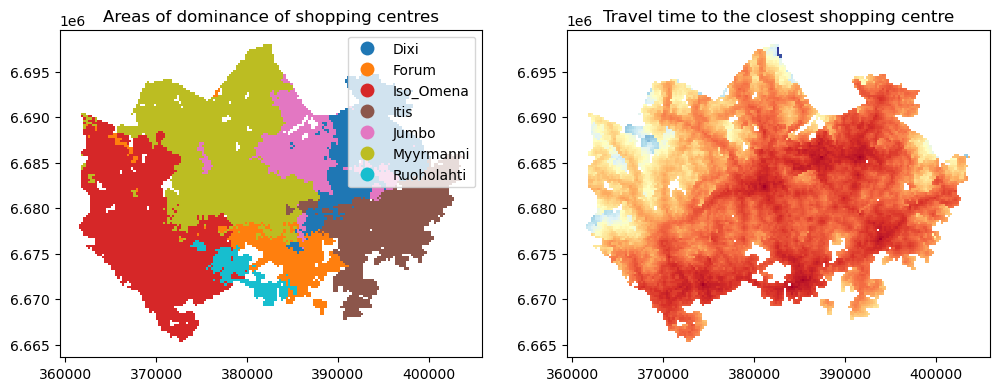

In [12]:
# Plot the areas of dominance and travel time to the closest centre
fig, (ax1,ax2) = plt.subplots(nrows=1,ncols=2, figsize=(12,6))
# Set titles
ax1.set_title('Areas of dominance of shopping centres')
ax2.set_title('Travel time to the closest shopping centre')
grid_j_r.plot(ax=ax1, column='min_travel_ind', legend=True)
grid_j_r.plot(ax=ax2, column=min_travel_time_col, legend=False, cmap='RdYlBu')
# Save figure in PNG with 300 DPI and tight bounding box
fig.savefig(DATA_DIRECTORY / "dominance_areas.png", dpi=300, bbox_inches='tight')

In [13]:
# NON-EDITABLE TEST CELL
# Check that output figure file exists
assert (DATA_DIRECTORY / "dominance_areas.png").exists()


--- 

**Do not forget to plot the result map, and save it to `DATA_DIRECTORY / "dominance_areas.png"`!**

---

## Reflections

This was a significantly more complex exercise that previous ones, and it included finding
a solution yourself. 

- What was most difficult part? 
- Where did you get stuck? 
- What was the easiest, and
- what was the most fun part of this exercise?

Add your answer below

- The most difficult part was the plotting. I kept getting `axes object is not subscriptable` error when trying to access `axes` array elements by `axes[0][0]` until I realized to unpack the axes on calling the `matplotlib.pyplot.subplots()`. When trying to access different axes with `axes[0]` it got a different error.
- On the plotting as described above
- The easiest part was calculating the `min` and `idxmin` columns
- The most entertaining part of the exercise was to construct the grid by looping through the travel time matrix text files. My function was perhaps unnecessarily complex but it made reading data and joins really clean. There was barely no need to clean the data after the joins and it had all the right columns. Also, it was blazingly fast to construct the grid by joining each read travel time matrix iteratively!


---

## Well done!

Congratulations, you completed exercise 4. Good Job!